In [234]:
from pathlib import Path
import numpy as np
import cv2
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras import models, layers
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, ConfusionMatrixDisplay

In [235]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("karapy/neurovision")

print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/datasets/karapy/neurovision


In [236]:
DATA = Path('/kaggle/input/datasets/karapy/neurovision/Data/')

In [237]:
# DATA = Path('/content/drive/MyDrive/NeuroVision/Data/raw/')
SIZE = (224, 224)
EXTS = {'.jpeg', '.jpg', '.bmp', '.png'}
RANDOM_SEED = 42

In [238]:
# get classes names

arr_names = []
for folder in DATA.iterdir():
    arr_names.append(folder.name)

arr_names

['glioma', 'meningioma', 'notumor', 'pituitary']

In [239]:

def load_dataset(data_dir=DATA, arr_names=arr_names):

    imgs_path_str, labels = [], []

    for class_name in arr_names:

        image_path = data_dir / class_name

        for path in image_path.iterdir():

            if path.suffix.lower() not in EXTS:
                continue

            imgs_path_str.append(str(path))
            labels.append(class_name)

    return np.array(imgs_path_str), np.array(labels)


In [240]:
imgs_path, labels = load_dataset()

print(imgs_path.shape, labels.shape)
print(imgs_path[0])
print(labels[0])
print(np.unique(labels, return_counts=True))

(7023,) (7023,)
/kaggle/input/datasets/karapy/neurovision/Data/glioma/Te-glTr_0000.jpg
glioma
(array(['glioma', 'meningioma', 'notumor', 'pituitary'], dtype='<U10'), array([1621, 1645, 2000, 1757]))


In [241]:
le = LabelEncoder()
labels_int = le.fit_transform(labels)

print("Class mapping:", dict(enumerate(le.classes_)))
print(labels_int[:5])

Class mapping: {0: np.str_('glioma'), 1: np.str_('meningioma'), 2: np.str_('notumor'), 3: np.str_('pituitary')}
[0 0 0 0 0]


In [242]:
X_train, X_temp, y_train, y_temp = train_test_split( imgs_path, labels_int, 
                                                            test_size=0.2, 
                                                            stratify=labels_int, 
                                                            random_state=RANDOM_SEED )

X_val, X_test, y_val, y_test = train_test_split( X_temp, y_temp, 
                                                        test_size=0.5, 
                                                        stratify=y_temp, 
                                                        random_state=RANDOM_SEED )

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (5618,) (5618,)
Validation: (702,) (702,)
Test: (703,) (703,)


In [243]:
train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train))

In [244]:
val_ds = tf.data.Dataset.from_tensor_slices((X_val, y_val))

In [245]:
test_ds = tf.data.Dataset.from_tensor_slices((X_test, y_test))

In [246]:
def load_img(path, label):
    img = tf.io.read_file(path)
 
    img = tf.io.decode_image( img, 
                             channels=3, 
                             expand_animations=False )

    # resize the img
    img = tf.image.resize(img, SIZE)

    # normalize pixel values
    img = img / 255.0

    return img, label

In [247]:
train_ds = train_ds.map(load_img).shuffle(len(X_train), seed=RANDOM_SEED).batch(32).prefetch(tf.data.AUTOTUNE)

In [248]:
val_ds = val_ds.map(load_img).batch(32).prefetch(tf.data.AUTOTUNE)

In [249]:
test_ds = test_ds.map(load_img).batch(32).prefetch(tf.data.AUTOTUNE)

In [250]:
img, label = next(iter(train_ds))

In [251]:
print("Image shape:", img.shape)
print("Image dtype:", img.dtype)
print("Label:", label.numpy())

Image shape: (32, 224, 224, 3)
Image dtype: <dtype: 'float32'>
Label: [0 2 2 2 1 0 1 2 2 3 3 0 3 1 0 0 0 3 1 2 2 0 3 2 0 3 2 3 2 3 1 2]


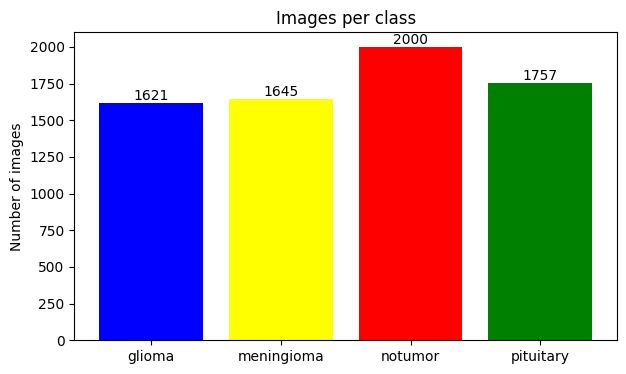

In [268]:
# class distrbution

classes, counts = np.unique(labels, return_counts=True)

plt.figure(figsize=(7, 4))
bars = plt.bar(classes, counts, color=['blue', 'yellow', 'red', 'green'])
plt.bar_label(bars)
plt.title("Images per class")
plt.ylabel("Number of images")
plt.show()

In [253]:
my_model = models.Sequential()

In [254]:
my_model.add(tf.keras.Input((224,224, 3)))

In [255]:
my_model.add(tf.keras.layers.Conv2D(filters=32, kernel_size=(3,3), padding='same',activation='relu', strides=1))
my_model.add(tf.keras.layers.MaxPool2D(pool_size=(2,2)))

In [256]:
my_model.add(tf.keras.layers.Conv2D(filters=64, kernel_size=(3, 3), padding="same", activation="relu", strides=1))
my_model.add(tf.keras.layers.MaxPooling2D((2, 2)))

In [257]:
my_model.add(tf.keras.layers.Conv2D(filters=128, kernel_size=(3, 3), padding="same", activation="relu", strides=1))
my_model.add(tf.keras.layers.MaxPooling2D((2, 2)))

In [258]:
my_model.add(tf.keras.layers.Conv2D(filters=256, kernel_size=(3, 3), padding="same", activation="relu", strides=1))
my_model.add(tf.keras.layers.MaxPooling2D((2, 2)))

In [259]:
my_model.add(tf.keras.layers.GlobalAveragePooling2D())

In [260]:
my_model.add(tf.keras.layers.Dense(units=128, activation='relu'))

In [261]:
my_model.add(tf.keras.layers.Dense(units=4, activation='softmax'))

In [262]:
my_model.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_22 (Conv2D)              │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_22 (MaxPooling2D) │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_23 (Conv2D)              │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_23 (MaxPooling2D) │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_24 (Conv2D)              │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_24 (MaxPooling2D) │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_25 (Conv2D)              │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_25 (MaxPooling2D) │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_7      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,828 (1.61 MB)

 Trainable params: 421,828 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

In [263]:
my_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [ ]:
early_stop = tf.keras.callbacks.EarlyStopping( monitor="val_loss", 
                                              patience=3, 
                                              restore_best_weights=True )

In [265]:
history = my_model.fit( train_ds, 
                       epochs=20, 
                       validation_data=val_ds, 
                       verbose=2, callbacks=[early_stop] )

Epoch 1/20
176/176 - 22s - 127ms/step - accuracy: 0.5018 - loss: 1.1008 - val_accuracy: 0.6610 - val_loss: 0.8723
Epoch 2/20
176/176 - 16s - 90ms/step - accuracy: 0.7029 - loss: 0.7486 - val_accuracy: 0.6624 - val_loss: 0.7575
Epoch 3/20
176/176 - 16s - 91ms/step - accuracy: 0.7488 - loss: 0.6281 - val_accuracy: 0.7635 - val_loss: 0.5442
Epoch 4/20
176/176 - 16s - 92ms/step - accuracy: 0.7869 - loss: 0.5322 - val_accuracy: 0.7949 - val_loss: 0.5104
Epoch 5/20
176/176 - 16s - 91ms/step - accuracy: 0.7905 - loss: 0.5162 - val_accuracy: 0.8148 - val_loss: 0.4667
Epoch 6/20
176/176 - 16s - 90ms/step - accuracy: 0.8252 - loss: 0.4622 - val_accuracy: 0.7920 - val_loss: 0.5640
Epoch 7/20
176/176 - 16s - 90ms/step - accuracy: 0.8252 - loss: 0.4482 - val_accuracy: 0.7920 - val_loss: 0.4968
Epoch 8/20
176/176 - 16s - 90ms/step - accuracy: 0.8339 - loss: 0.4235 - val_accuracy: 0.8362 - val_loss: 0.4059
Epoch 9/20
176/176 - 16s - 90ms/step - accuracy: 0.8425 - loss: 0.3947 - val_accuracy: 0.8162 -

In [266]:
test_loss, test_accuracy = my_model.evaluate(test_ds, verbose=2)

print(f"Test accuracy: {test_accuracy:.2%}")
print(f"Test loss: {test_loss:.4f}")

22/22 - 1s - 45ms/step - accuracy: 0.8947 - loss: 0.2854
Test accuracy: 89.47%
Test loss: 0.2854


In [278]:
y_test[0]

np.int64(3)

In [286]:
model_pred = my_model.predict(test_ds)

22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step


In [289]:
pred_labels = np.argmax(model_pred, axis=1)

In [290]:
np.unique(pred_labels)

array([0, 1, 2, 3])

Text(0.5, 1.0, 'y_true : pituitary')

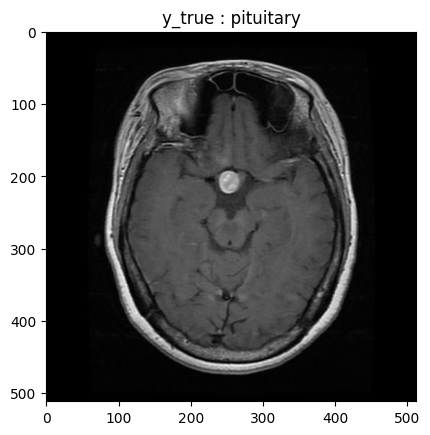

In [299]:
test_img = cv2.imread(X_test[0])
test_label = le.inverse_transform([y_test[0]])[0]
plt.imshow(test_img)
plt.title(f'y_true : {test_label}')

Text(0.5, 1.0, 'y_pred : pituitary')

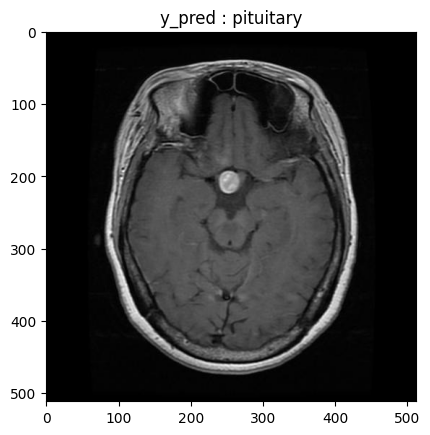

In [298]:
pred_label = le.inverse_transform([pred_labels[0]])[0]
plt.imshow(test_img)
plt.title(f'y_pred : {pred_label}')

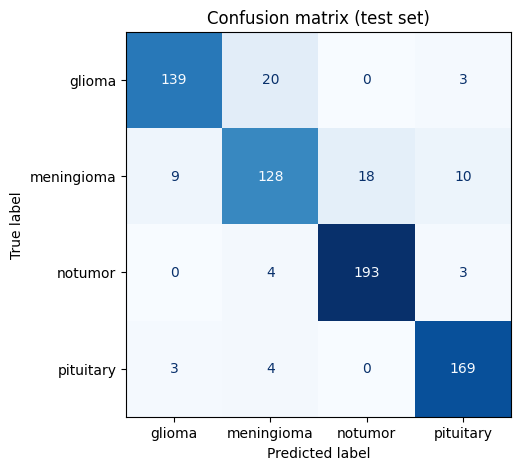

              precision    recall  f1-score   support

      glioma      0.921     0.858     0.888       162
  meningioma      0.821     0.776     0.798       165
     notumor      0.915     0.965     0.939       200
   pituitary      0.914     0.960     0.936       176

    accuracy                          0.895       703
   macro avg      0.892     0.890     0.890       703
weighted avg      0.894     0.895     0.893       703



In [300]:
cm = confusion_matrix(y_test, pred_labels)
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=arr_names).plot(ax=ax, cmap="Blues", colorbar=False)
plt.title("Confusion matrix (test set)")
plt.show()

print(classification_report(y_test, pred_labels, target_names=arr_names, digits=3))

In [301]:
my_model.save("neurovision_model.keras")